# Notebook nộp bài — Phân cụm 63 tỉnh Việt Nam với STING trên dữ liệu PAPI

**Đồ án môn Học máy** · Topic 6: *Grid-based (clustering)* · Domain: Sociology / History.

## 0. Mục tiêu & cách chạy

- **Mục tiêu:** trình bày lý thuyết STING, cài đặt lại từ đầu (`src/sting.py`), kiểm chứng
  trên dữ liệu tổng hợp bằng ARI, rồi áp dụng lên panel PAPI 63 tỉnh 2011–2024, so sánh với
  k-means/DBSCAN và khảo sát độ nhạy tham số; cuối cùng minh họa mô hình giám sát Ridge/RF
  với holdout 2023→2024.
- **Cách chạy:** `python scripts/gen_submission_demo.py` (sinh + execute notebook này) hoặc
  `python -m nbconvert --to notebook --execute --inplace notebooks/submission_demo.ipynb`.
- Mọi số liệu được **tính lại từ dữ liệu** ngay trong notebook và đối chiếu (`assert`) với
  `results/*.csv|md`; không hardcode.

In [1]:
import sys
from pathlib import Path

ROOT = None
for cand in (Path.cwd(), Path.cwd().parent):
    if (cand / "src" / "sting.py").exists():
        ROOT = cand
        sys.path.insert(0, str(cand / "src"))
        sys.path.insert(0, str(cand / "scripts"))
        break

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import (
    adjusted_rand_score,
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
)

from sting import STING
from papi_pred_common import (
    FEATURE_LABELS,
    REGRESSION_FEATURES,
    load_config,
    load_panel,
    select_model_by_cv,
)
from predict_supervised import HOLDOUT_YEAR, build_regression_pairs, expanding_origin_folds
from fig_style import CLUSTER_COLORS, CLUSTER_LABELS, apply_style

apply_style()
print("import OK | ROOT =", ROOT)

import OK | ROOT = D:\gbs-wt\nbfix


## 1. Lý thuyết STING

STING (STatistical INformation Grid — Wang, Yang & Muntz, VLDB 1997) chia không gian đặc trưng
thành **lưới phân cấp** và lưu thống kê cho từng ô, thay vì quét từng cặp điểm.

### 1.1 Lưới phân cấp (hierarchical grid)
- Mức $l$ chia mỗi chiều thành $factor^l$ đoạn bằng nhau → mức 0 = 1 ô duy nhất; mức $l$ có tới
  $factor^{l \cdot d}$ ô ($d$ = số chiều).
- Mỗi ô xác định bởi chỉ số $(i_1, \dots, i_d)$ và lưu thống kê **độc lập theo từng chiều**:
  count, mean, std, min, max. Bài gốc (Wang et al.) còn lưu **loại phân phối** (distribution type);
  **cài đặt của chúng ta bỏ qua distribution type (đơn giản hóa)**.

### 1.2 Thống kê mỗi ô
Với ô $c$ chứa $n_c$ điểm:
$$\mu_j(c) = \frac{1}{n_c}\sum_{x \in c} x_j, \qquad
\sigma_j^2(c) = \frac{1}{n_c}\sum_{x \in c}\bigl(x_j - \mu_j(c)\bigr)^2$$
Một ô "dày" (dense) khi $count(c) \ge min\_count$. (Chỉ count/mean/std/min/max — không có distribution type như bài gốc.)

### 1.3 STING gốc (top-down) vs cài đặt `src/sting.py`
**Bài gốc:** truy vấn/phân tích **top-down** — bắt đầu từ lớp cao, kiểm định mức liên quan thống kê
của từng ô (confidence), chỉ hạ xuống các ô con của ô “có liên quan”; nhờ đó cắt tỉa không gian tìm kiếm.

**Cài đặt của chúng ta (đơn giản hóa):** `fit()` xây lưới **từng mức một** (level 0 → … → cuối),
không có bước cắt tỉa theo confidence như bài gốc. `query_rect` quét mọi ô tại **một mức `level` chọn sẵn**
và cộng dồn thống kê các ô nằm **trọn** trong vùng chữ nhật — không quét lại điểm thô, nhưng **không**
phải truy vấn top-down. `cluster()` cũng gom các ô dày liền kề tại **một mức cố định** (tham số `level`).

### 1.4 Hợp ô liền kề (connected components)
Các ô dày liền kề được gom thành cụm bằng DFS. `connectivity=1` gom ô kề **mặt** (4 hướng trong
2D); `connectivity=d` gom thêm ô kề **góc** (8 hướng). Điểm thuộc ô không dày nhận nhãn
**nhiễu (−1)** — STING không ép mọi điểm vào cụm.

### 1.5 Độ phức tạp
Dữ liệu quét **1 lượt cho mỗi mức** → xây lưới là $O(n)$ theo số điểm (mỗi mức thêm hệ số
$factor^d$ ô, không đổi theo $n$).

### 1.6 So sánh k-means / DBSCAN
| | k-means | DBSCAN | STING |
|---|---|---|---|
| Mô hình | centroid | mật độ điểm | lưới + thống kê ô |
| Hình dạng cụm | cầu (convex) | bất kỳ | bất kỳ (theo ô) |
| Nhiễu | gán hết điểm | nhãn −1 | nhãn −1 |
| Chi phí | $O(nkd)$/vòng | $O(n \log n)$ (có chỉ mục) | $O(n)$ |
| Tham số chính | $k$ | $eps, min\_samples$ | $factor, min\_count, level$ |

## 2. Cài đặt từ đầu — ví dụ chạy từng bước

Dùng `src/sting.py` (STING tự viết, không thư viện ngoài). Ví dụ nhỏ 2D với 2 cụm + vài điểm
ngoại vi để thấy rõ cơ chế lưới phân cấp: **mức 1 → mức 2**, bảng thống kê vài ô, rồi gom cụm.

In [2]:
rng = np.random.default_rng(7)
X_blob, _ = make_blobs(n_samples=90, centers=[(-4, -4), (4, 4)],
                       cluster_std=0.7, random_state=7)
X_out = rng.uniform(-9, 9, size=(6, 2))
X = np.vstack([X_blob, X_out])

model = STING(n_levels=3, factor=2, min_count=3).fit(X)
for level in range(model.n_levels):
    counts = np.array([c.count for c in model.cells_[level].values()])
    print(f"Mức {level}: {len(model.cells_[level])} ô có dữ liệu | "
          f"tổng điểm = {counts.sum()} | ô đông nhất = {counts.max()}")

Mức 0: 1 ô có dữ liệu | tổng điểm = 96 | ô đông nhất = 96
Mức 1: 4 ô có dữ liệu | tổng điểm = 96 | ô đông nhất = 46
Mức 2: 8 ô có dữ liệu | tổng điểm = 96 | ô đông nhất = 45


In [3]:
level = 2
rows = []
for cell in model.cells_[level].values():
    rows.append({
        "ô": cell.index,
        "count": cell.count,
        "mean x1": round(cell.mean[0], 2),
        "mean x2": round(cell.mean[1], 2),
        "std x1": round(cell.std[0], 2),
    })
df_cells = pd.DataFrame(rows).sort_values("count", ascending=False)
print(f"Bảng thống kê các ô đông nhất ở mức {level}:")
print(df_cells.head(6).to_string(index=False))

Bảng thống kê các ô đông nhất ở mức 2:
     ô  count  mean x1  mean x2  std x1
(1, 0)     45    -3.89    -4.08    0.63
(3, 3)     27     3.91     4.54    0.78
(3, 2)     19     3.89     3.41    0.57
(0, 0)      1    -5.45    -4.46    0.00
(1, 3)      1    -3.60     6.72    0.00
(0, 3)      1    -8.91     5.78    0.00


k = 2 | cỡ cụm = [46, 45] | nhiễu = 5.2%


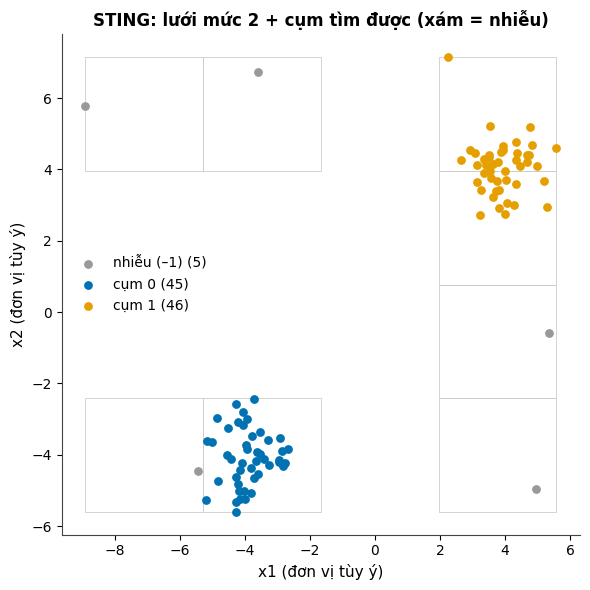

In [4]:
labels = model.cluster(level=2, connectivity=1)
sizes = sorted([int((labels == c).sum()) for c in range(model.n_clusters_)], reverse=True)
print(f"k = {model.n_clusters_} | cỡ cụm = {sizes} | nhiễu = {(labels == -1).mean():.1%}")

fig, ax = plt.subplots(figsize=(6, 6))
step = (model.bounds_max_ - model.bounds_min_) / (model.factor ** 2)
for cell in model.cells_[2].values():
    x0, y0 = cell.bounds_min
    ax.add_patch(plt.Rectangle((x0, y0), step[0], step[1], fill=False,
                               edgecolor="#cccccc", linewidth=0.6))
for c in sorted(set(labels.tolist())):
    m = labels == c
    ax.scatter(X[m, 0], X[m, 1], s=28, c=CLUSTER_COLORS.get(c, "#333333"),
               label=CLUSTER_LABELS.get(c, f"cụm {c}") + f" ({int(m.sum())})")
ax.set_title("STING: lưới mức 2 + cụm tìm được (xám = nhiễu)")
ax.set_xlabel("x1 (đơn vị tùy ý)")
ax.set_ylabel("x2 (đơn vị tùy ý)")
ax.legend()
plt.tight_layout()
plt.show()

## 3. Kiểm chứng tổng hợp (ARI)

Kiểm chứng cài đặt bằng **ARI** trên dữ liệu giả lập 2 cụm tách biệt (seed cố định) — cùng gate
với `tests/test_sting.py::test_two_blobs_recovered` (ARI ≥ 0.9). Sau đó xem độ nhạy theo `min_count`.

In [5]:
X_syn, y_true = make_blobs(n_samples=240, centers=[(-6, -6), (6, 6)],
                           cluster_std=0.6, random_state=42)
m_syn = STING(n_levels=3, factor=4, min_count=3).fit(X_syn)
lab_syn = m_syn.cluster(level=2, connectivity=1)
ari = adjusted_rand_score(y_true, lab_syn)
assert ari >= 0.9, f"ARI quá thấp: {ari:.3f}"
print(f"ARI = {ari:.3f} | nhiễu = {(lab_syn == -1).mean():.1%} | k = {m_syn.n_clusters_}")
print("Khớp gate tests/test_sting.py::test_two_blobs_recovered (ARI >= 0.9).")

rows = []
for mc in (2, 3, 5, 8, 12):
    mm = STING(n_levels=3, factor=4, min_count=mc).fit(X_syn)
    ll = mm.cluster(level=2, connectivity=1)
    rows.append((mc, adjusted_rand_score(y_true, ll), (ll == -1).mean(), mm.n_clusters_))
print(f"{'min_count':>9} | {'ARI':>6} | {'noise':>7} | k")
for mc, a, nz, k in rows:
    print(f"{mc:>9} | {a:>6.3f} | {nz:>7.1%} | {k}")

ARI = 0.950 | nhiễu = 2.5% | k = 2
Khớp gate tests/test_sting.py::test_two_blobs_recovered (ARI >= 0.9).
min_count |    ARI |   noise | k
        2 |  0.983 |    0.8% | 2
        3 |  0.950 |    2.5% | 2
        5 |  0.863 |    7.1% | 2
        8 |  0.696 |   17.5% | 2
       12 |  0.452 |   34.6% | 2


## 4. Ứng dụng PAPI

**Tiền xử lý / chuẩn hóa (nêu lý do):**
- Panel `papi_panel_63_2011_2024.csv` đã sạch: `0.0` quy về NaN (khớp quy ước gói replication Mendeley);
  23/37 chỉ tiêu bị đánh dấu bởi kiểm tra heuristic (bước nhảy trung bình > 0.25); chưa chứng minh là
  đổi thang — các cột đó bị loại khỏi pipeline xuyên năm (chỉ dùng chỉ tiêu qua audit; ví dụ đã chứng minh:
  `sd_5_4`, xem `data/raw/papi/PROVENANCE.md`).
- Chọn cặp chỉ tiêu đóng băng `sd_4_2 × sd_6_1` (theo `models/predict_config.json`, chọn bằng quy trình
  train-only — không nhìn 2024).
- **Chuẩn hóa z-score** từng cột (`StandardScaler`) để hai trục có cùng thang, biên ô lưới không bị lệch
  theo giá trị tuyệt đối của một chỉ tiêu; STING bất biến với biến đổi affine từng chiều nên nhãn không
  đổi, chỉ đổi độ rộng ô tương đối.

In [6]:
cfg = load_config()
feats = cfg["features"]
panel = load_panel()
print("Panel:", panel.shape, "| tỉnh:", panel.province_code.nunique(),
      "| năm:", panel.year.min(), "→", panel.year.max())
assert panel.shape == (882, 41)
print("Đặc trưng đóng băng:", feats, "→", [FEATURE_LABELS[f] for f in feats])

Panel: (882, 41) | tỉnh: 63 | năm: 2011 → 2024
Đặc trưng đóng băng: ['sd_4_2', 'sd_6_1'] → ['4.2 Kiểm soát tham nhũng trong cung ứng dịch vụ công', '6.1 Y tế công lập']


In [7]:
ptr = panel[panel.year <= 2023].dropna(subset=feats)
scaler = StandardScaler().fit(ptr[feats])
Xz = scaler.transform(ptr[feats])
m_frozen = STING(n_levels=cfg["sting"]["n_levels"], factor=cfg["sting"]["factor"],
                 min_count=cfg["sting"]["min_count"]).fit(Xz)
lab = m_frozen.cluster(level=cfg["sting"]["cluster_level"],
                       connectivity=cfg["sting"]["connectivity"])
sizes = sorted([int((lab == c).sum()) for c in range(m_frozen.n_clusters_)], reverse=True)
noise = float((lab == -1).mean())
print(f"STING frozen: k={m_frozen.n_clusters_} | cỡ={sizes} | nhiễu={noise:.1%} (n={len(ptr)})")
assert m_frozen.n_clusters_ == 3
assert sizes == [629, 16, 5]
assert abs(noise - 0.196) < 1e-3

STING frozen: k=3 | cỡ=[629, 16, 5] | nhiễu=19.6% (n=808)


In [8]:
saved = pd.read_csv(ROOT / "results" / "predict_all_years.csv", encoding="utf-8-sig")


def refit_labels(df, feats, sp):
    train = df[df.year <= 2023]
    ptr = train[feats].dropna()
    sc = StandardScaler().fit(ptr)
    model = STING(n_levels=sp["n_levels"], factor=sp["factor"],
                  min_count=sp["min_count"]).fit(sc.transform(ptr))
    model.cluster(level=sp["cluster_level"], connectivity=sp["connectivity"])
    rows = []
    for year in sorted(df.year.unique()):
        sub = df[df.year == year].dropna(subset=feats)
        if sub.empty:
            continue
        pred = model.predict(sc.transform(sub[feats]))
        rows.append(pd.DataFrame({"year": int(year),
                                  "province_code": sub["province_code"].to_numpy(),
                                  "pred_cluster": pred}))
    return pd.concat(rows, ignore_index=True)


refit = refit_labels(panel, feats, cfg["sting"])
merged = saved.merge(refit, on=["year", "province_code"], suffixes=("_saved", "_refit"))
n_diff = int((merged.pred_cluster_saved != merged.pred_cluster_refit).sum())
assert len(merged) == len(saved) == 869
assert n_diff == 0
print(f"Refit khớp {len(saved)}/{len(saved)} nhãn (0 lệch) — gate test_artifact_reproduction.")

Refit khớp 869/869 nhãn (0 lệch) — gate test_artifact_reproduction.


In [9]:
metrics = pd.read_csv(ROOT / "results" / "metrics.csv")
metrics_pooled = metrics[metrics.scope == "pooled 2011-2023"]
print(metrics_pooled.to_string(index=False))
print()


def safe_metrics(X, lab):
    mask = lab >= 0
    k = len(set(lab[mask]))
    if k < 2:
        return None, None, None
    return (silhouette_score(X[mask], lab[mask]),
            davies_bouldin_score(X[mask], lab[mask]),
            calinski_harabasz_score(X[mask], lab[mask]))


sil, db, ch = safe_metrics(Xz, lab)
sting_row = metrics_pooled[metrics_pooled.method == "STING (frozen)"].iloc[0]
assert abs(sil - sting_row.silhouette) < 1e-3
assert abs(db - sting_row.davies_bouldin) < 1e-3
assert abs(ch - sting_row.calinski_harabasz) < 1e-1

km2 = KMeans(n_clusters=2, n_init=10, random_state=42).fit(Xz)
km2_row = metrics_pooled[metrics_pooled.method == "k-means k=2"].iloc[0]
assert abs(adjusted_rand_score(lab, km2.labels_) - km2_row.ari_vs_sting) < 1e-3
assert abs(silhouette_score(Xz, km2.labels_) - km2_row.silhouette) < 1e-3

db2 = DBSCAN(eps=0.2, min_samples=5).fit(Xz)
db2_row = metrics_pooled[metrics_pooled.method == "DBSCAN eps=0.2"].iloc[0]
assert abs(adjusted_rand_score(lab, db2.labels_) - db2_row.ari_vs_sting) < 1e-3
print("STING frozen + k-means k=2 + DBSCAN eps=0.2: khớp metrics.csv (đã assert).")

           scope         method  k  noise_ratio  silhouette  davies_bouldin  calinski_harabasz  ari_vs_sting                                             note
pooled 2011-2023 STING (frozen)  3        0.196       0.361           0.472               62.0           NaN k=3: [629,16,5]; noise tách khỏi metric hình học
pooled 2011-2023    k-means k=2  2        0.000       0.445           0.876              812.3         0.166                         tất cả điểm được gán cụm
pooled 2011-2023    k-means k=3  3        0.000       0.336           1.050              665.7         0.139                         tất cả điểm được gán cụm
pooled 2011-2023    k-means k=4  4        0.000       0.364           0.879              669.1         0.082                         tất cả điểm được gán cụm
pooled 2011-2023    k-means k=5  5        0.000       0.334           0.945              647.9         0.070                         tất cả điểm được gán cụm
pooled 2011-2023 DBSCAN eps=0.2  5        0.142     

STING frozen + k-means k=2 + DBSCAN eps=0.2: khớp metrics.csv (đã assert).


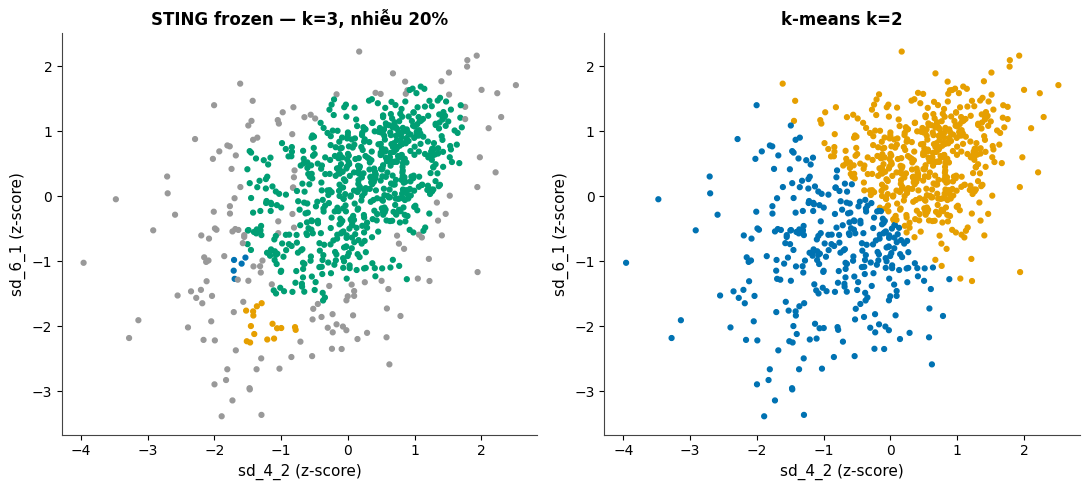

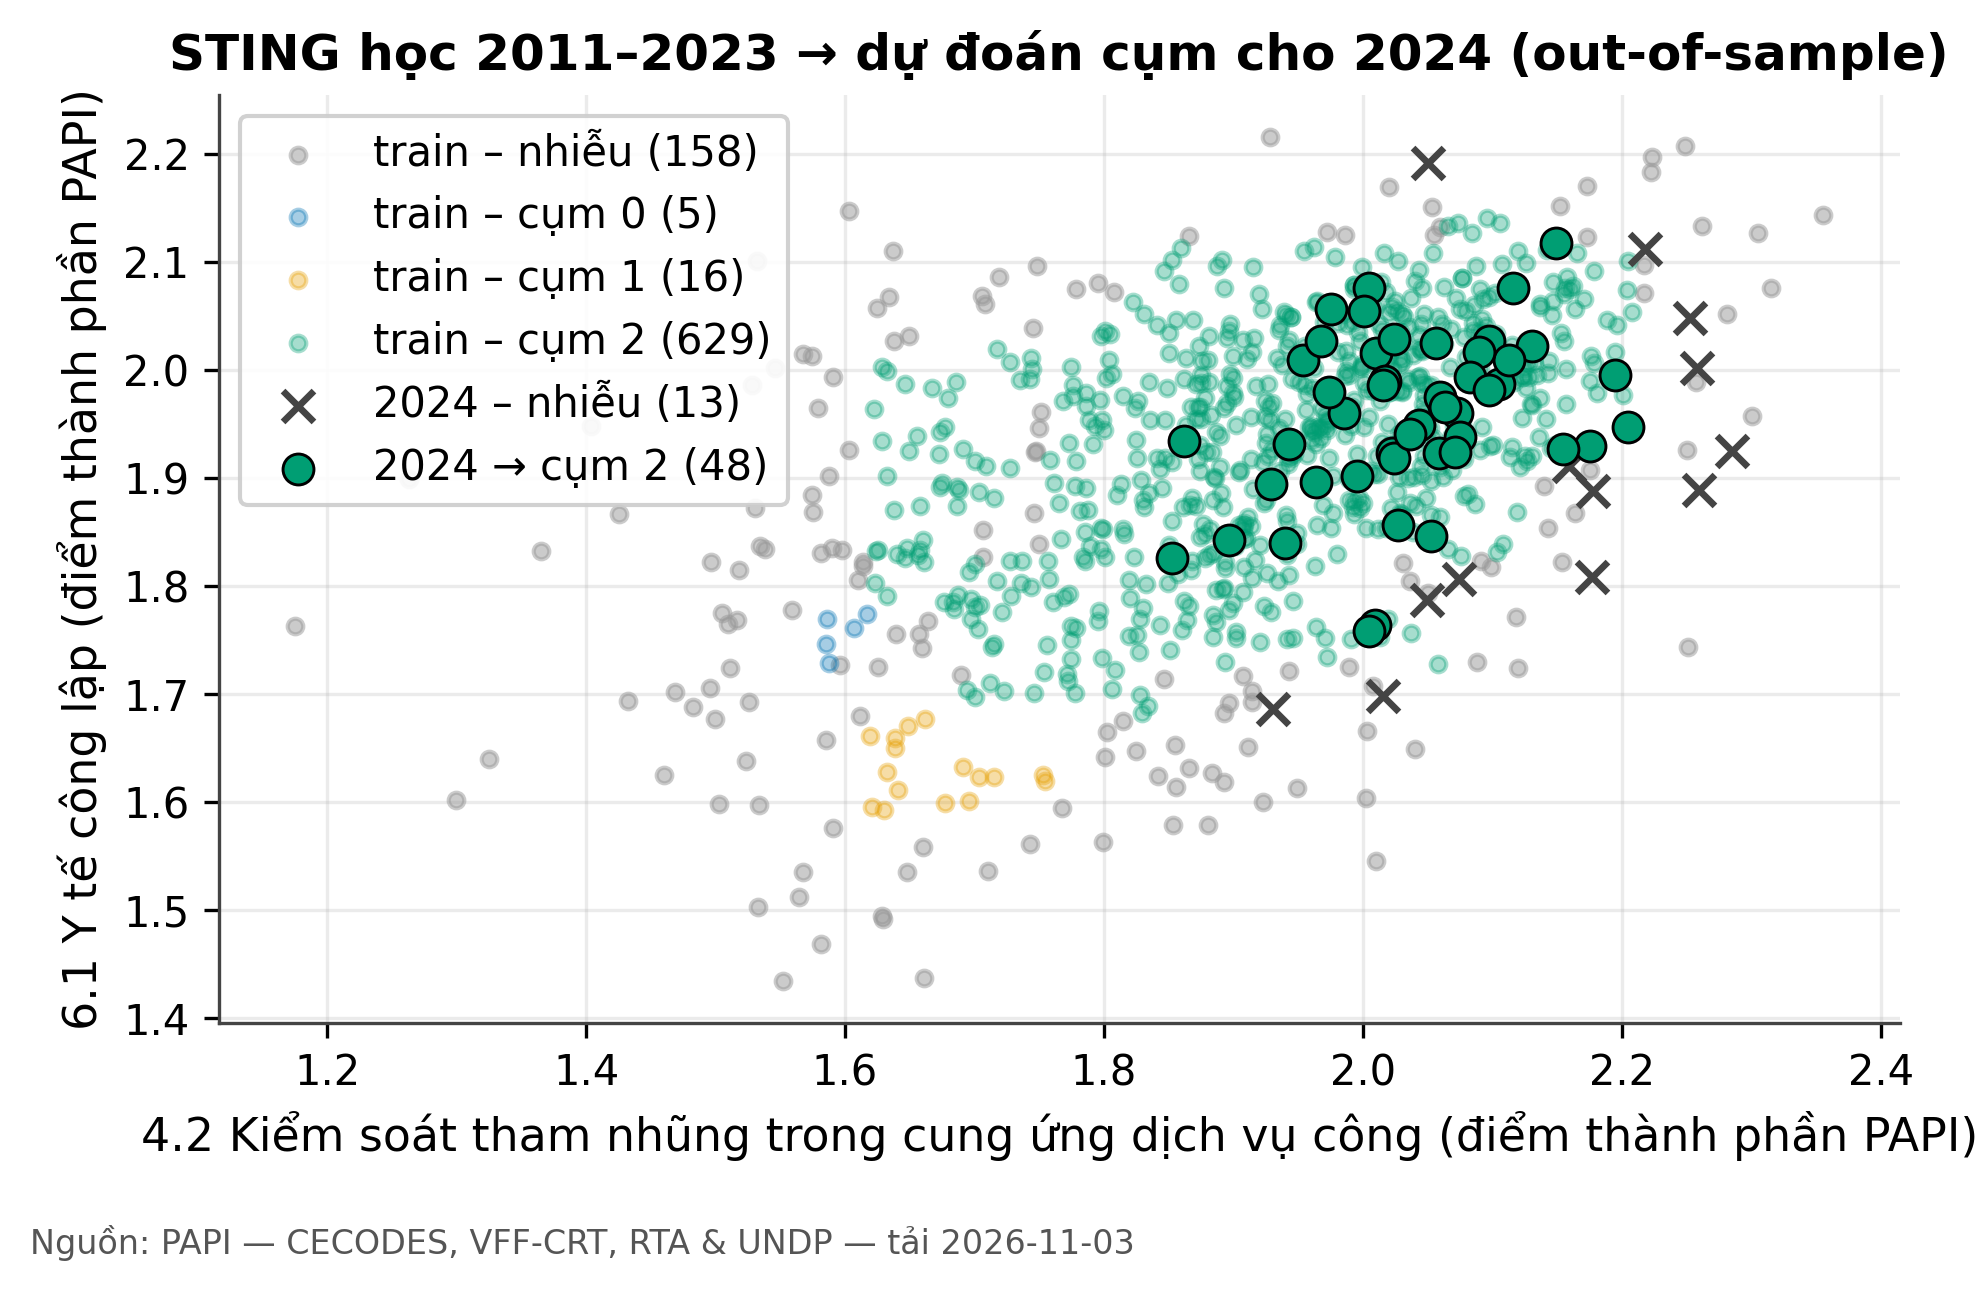

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
axes[0].scatter(Xz[:, 0], Xz[:, 1], s=12, c=[CLUSTER_COLORS[int(c)] for c in lab])
axes[0].set_title(f"STING frozen — k=3, nhiễu {noise:.0%}")
axes[1].scatter(Xz[:, 0], Xz[:, 1], s=12, c=[CLUSTER_COLORS[int(c)] for c in km2.labels_])
axes[1].set_title("k-means k=2")
for ax in axes:
    ax.set_xlabel(f"{feats[0]} (z-score)")
    ax.set_ylabel(f"{feats[1]} (z-score)")
plt.tight_layout()
plt.show()

display(Image(filename=str(ROOT / "results" / "figs" / "predict_2024.png")))

In [11]:
test2024 = panel[panel.year == 2024].dropna(subset=feats)
Xte = scaler.transform(test2024[feats])
base = m_frozen.predict(Xte)
print(f"Dự đoán 2024 (out-of-sample): phủ {(base != -1).mean():.0%} | "
      f"phân bố {dict(sorted({int(k): int((base == k).sum()) for k in set(base)}.items()))}")

sens = []
for mc in (3, 5, 8):
    mm = STING(n_levels=cfg["sting"]["n_levels"], factor=cfg["sting"]["factor"],
               min_count=mc).fit(Xz)
    mm.cluster(level=cfg["sting"]["cluster_level"], connectivity=cfg["sting"]["connectivity"])
    p = mm.predict(Xte)
    sens.append((mc, round(float((p != -1).mean()), 2), mm.n_clusters_,
                 round(float(adjusted_rand_score(p, base)), 3)))
print(f"{'min_count':>9} | {'coverage 2024':>13} | k | ARI vs chốt")
for mc, cov, k, ari in sens:
    print(f"{mc:>9} | {cov:>13.0%} | {k} | {ari:.3f}")
cov_map = {mc: round(cov, 2) for mc, cov, _, _ in sens}
ari_map = {mc: round(ari, 3) for mc, _, _, ari in sens}
assert cov_map[3] == 0.82 and cov_map[5] == 0.79 and cov_map[8] == 0.70
assert ari_map[3] == 0.852 and ari_map[5] == 1.0 and ari_map[8] == 0.678
print("Độ nhạy min_count khớp results/predict_summary.md (đã assert).")

Dự đoán 2024 (out-of-sample): phủ 79% | phân bố {-1: 13, 2: 48}
min_count | coverage 2024 | k | ARI vs chốt
        3 |           82% | 3 | 0.852
        5 |           79% | 3 | 1.000
        8 |           70% | 1 | 0.678
Độ nhạy min_count khớp results/predict_summary.md (đã assert).


## 5. Mô hình giám sát: Ridge/RF

Dự báo *6.1 Y tế công lập* năm sau từ 8 chỉ tiêu sạch của năm hiện tại:
- **CV expanding-origin** (train-only) 2017–2022, warm-up 2011–2016 — chọn model theo R² CV, không nhìn holdout.
- **Holdout 2023→2024** đánh giá đúng MỘT lần.
- Nạp lại `models/*.joblib` (không cần huấn luyện lại) và dự báo cho 1 mẫu 8 chỉ tiêu.

In [12]:
P = build_regression_pairs(panel)
tr = P[P.year_t < HOLDOUT_YEAR]
te = P[P.year_t == HOLDOUT_YEAR]
print(f"Regression: train {len(tr)} cặp (2011–2022) · holdout {len(te)} cặp (2023→2024)")
assert len(tr) == 740 and len(te) == 59

training_origins = tr["year_t"].to_numpy()
folds = expanding_origin_folds(training_origins, first_validation_origin=2017)
for n, (ti, vi) in enumerate(folds, start=1):
    print(f"Fold {n}: max train origin={training_origins[ti].max()}, "
          f"validation origin={training_origins[vi][0]}")

Regression: train 740 cặp (2011–2022) · holdout 59 cặp (2023→2024)
Fold 1: max train origin=2016, validation origin=2017
Fold 2: max train origin=2017, validation origin=2018
Fold 3: max train origin=2018, validation origin=2019
Fold 4: max train origin=2019, validation origin=2020
Fold 5: max train origin=2020, validation origin=2021
Fold 6: max train origin=2021, validation origin=2022


In [13]:
sup = pd.read_csv(ROOT / "results" / "supervised_metrics.csv")
reg = sup[sup.task == "regression"]
print(reg.to_string(index=False))
print()

reg_models = reg[~reg.model.isin(
    ["carry-forward (giữ giá trị năm nay)", "trung bình train"]
)].dropna(subset=["value_cv"])
chosen = select_model_by_cv(reg_models)
chosen_row = reg[reg.model == chosen].iloc[0]
print(f"Model chọn theo CV: {chosen} (R² CV = {chosen_row.value_cv:.3f})")
assert chosen == "ridge"
assert abs(chosen_row.value_cv - 0.265) < 1e-3
assert abs(chosen_row.holdout_mae - 0.064) < 1e-3

carry = reg[reg.model == "carry-forward (giữ giá trị năm nay)"].iloc[0]
improve = (1 - chosen_row.holdout_mae / carry.holdout_mae) * 100
print(f"Ridge MAE holdout {chosen_row.holdout_mae:.4f} thấp hơn carry-forward "
      f"{carry.holdout_mae:.4f} → {improve:.1f}%")
assert abs(improve - 6.3) < 0.1

      task                               model                       metric_cv  value_cv  holdout_mae  holdout_rmse  holdout_r2  holdout_acc  holdout_macro_f1
regression carry-forward (giữ giá trị năm nay) r2 (expanding origin 2017–2022)     0.145       0.0683        0.0875       0.198          NaN               NaN
regression                    trung bình train r2 (expanding origin 2017–2022)    -0.770       0.0814        0.1027      -0.105          NaN               NaN
regression                               ridge r2 (expanding origin 2017–2022)     0.265       0.0640        0.0769       0.381          NaN               NaN
regression                       random forest r2 (expanding origin 2017–2022)     0.197       0.0616        0.0742       0.423          NaN               NaN

Model chọn theo CV: ridge (R² CV = 0.265)
Ridge MAE holdout 0.0640 thấp hơn carry-forward 0.0683 → 6.3%


8 đặc trưng đầu vào: ['sd_1_3', 'sd_1_4', 'sd_4_1', 'sd_4_2', 'sd_4_3', 'sd_4_4', 'sd_6_1', 'sd_6_3']
Vector mẫu: [1.5, 2.6, 2.0, 2.1, 1.9, 1.7, 1.9, 1.8]
Dự báo 6.1 Y tế công lập năm sau — Ridge: 1.9683 | RF: 1.8816


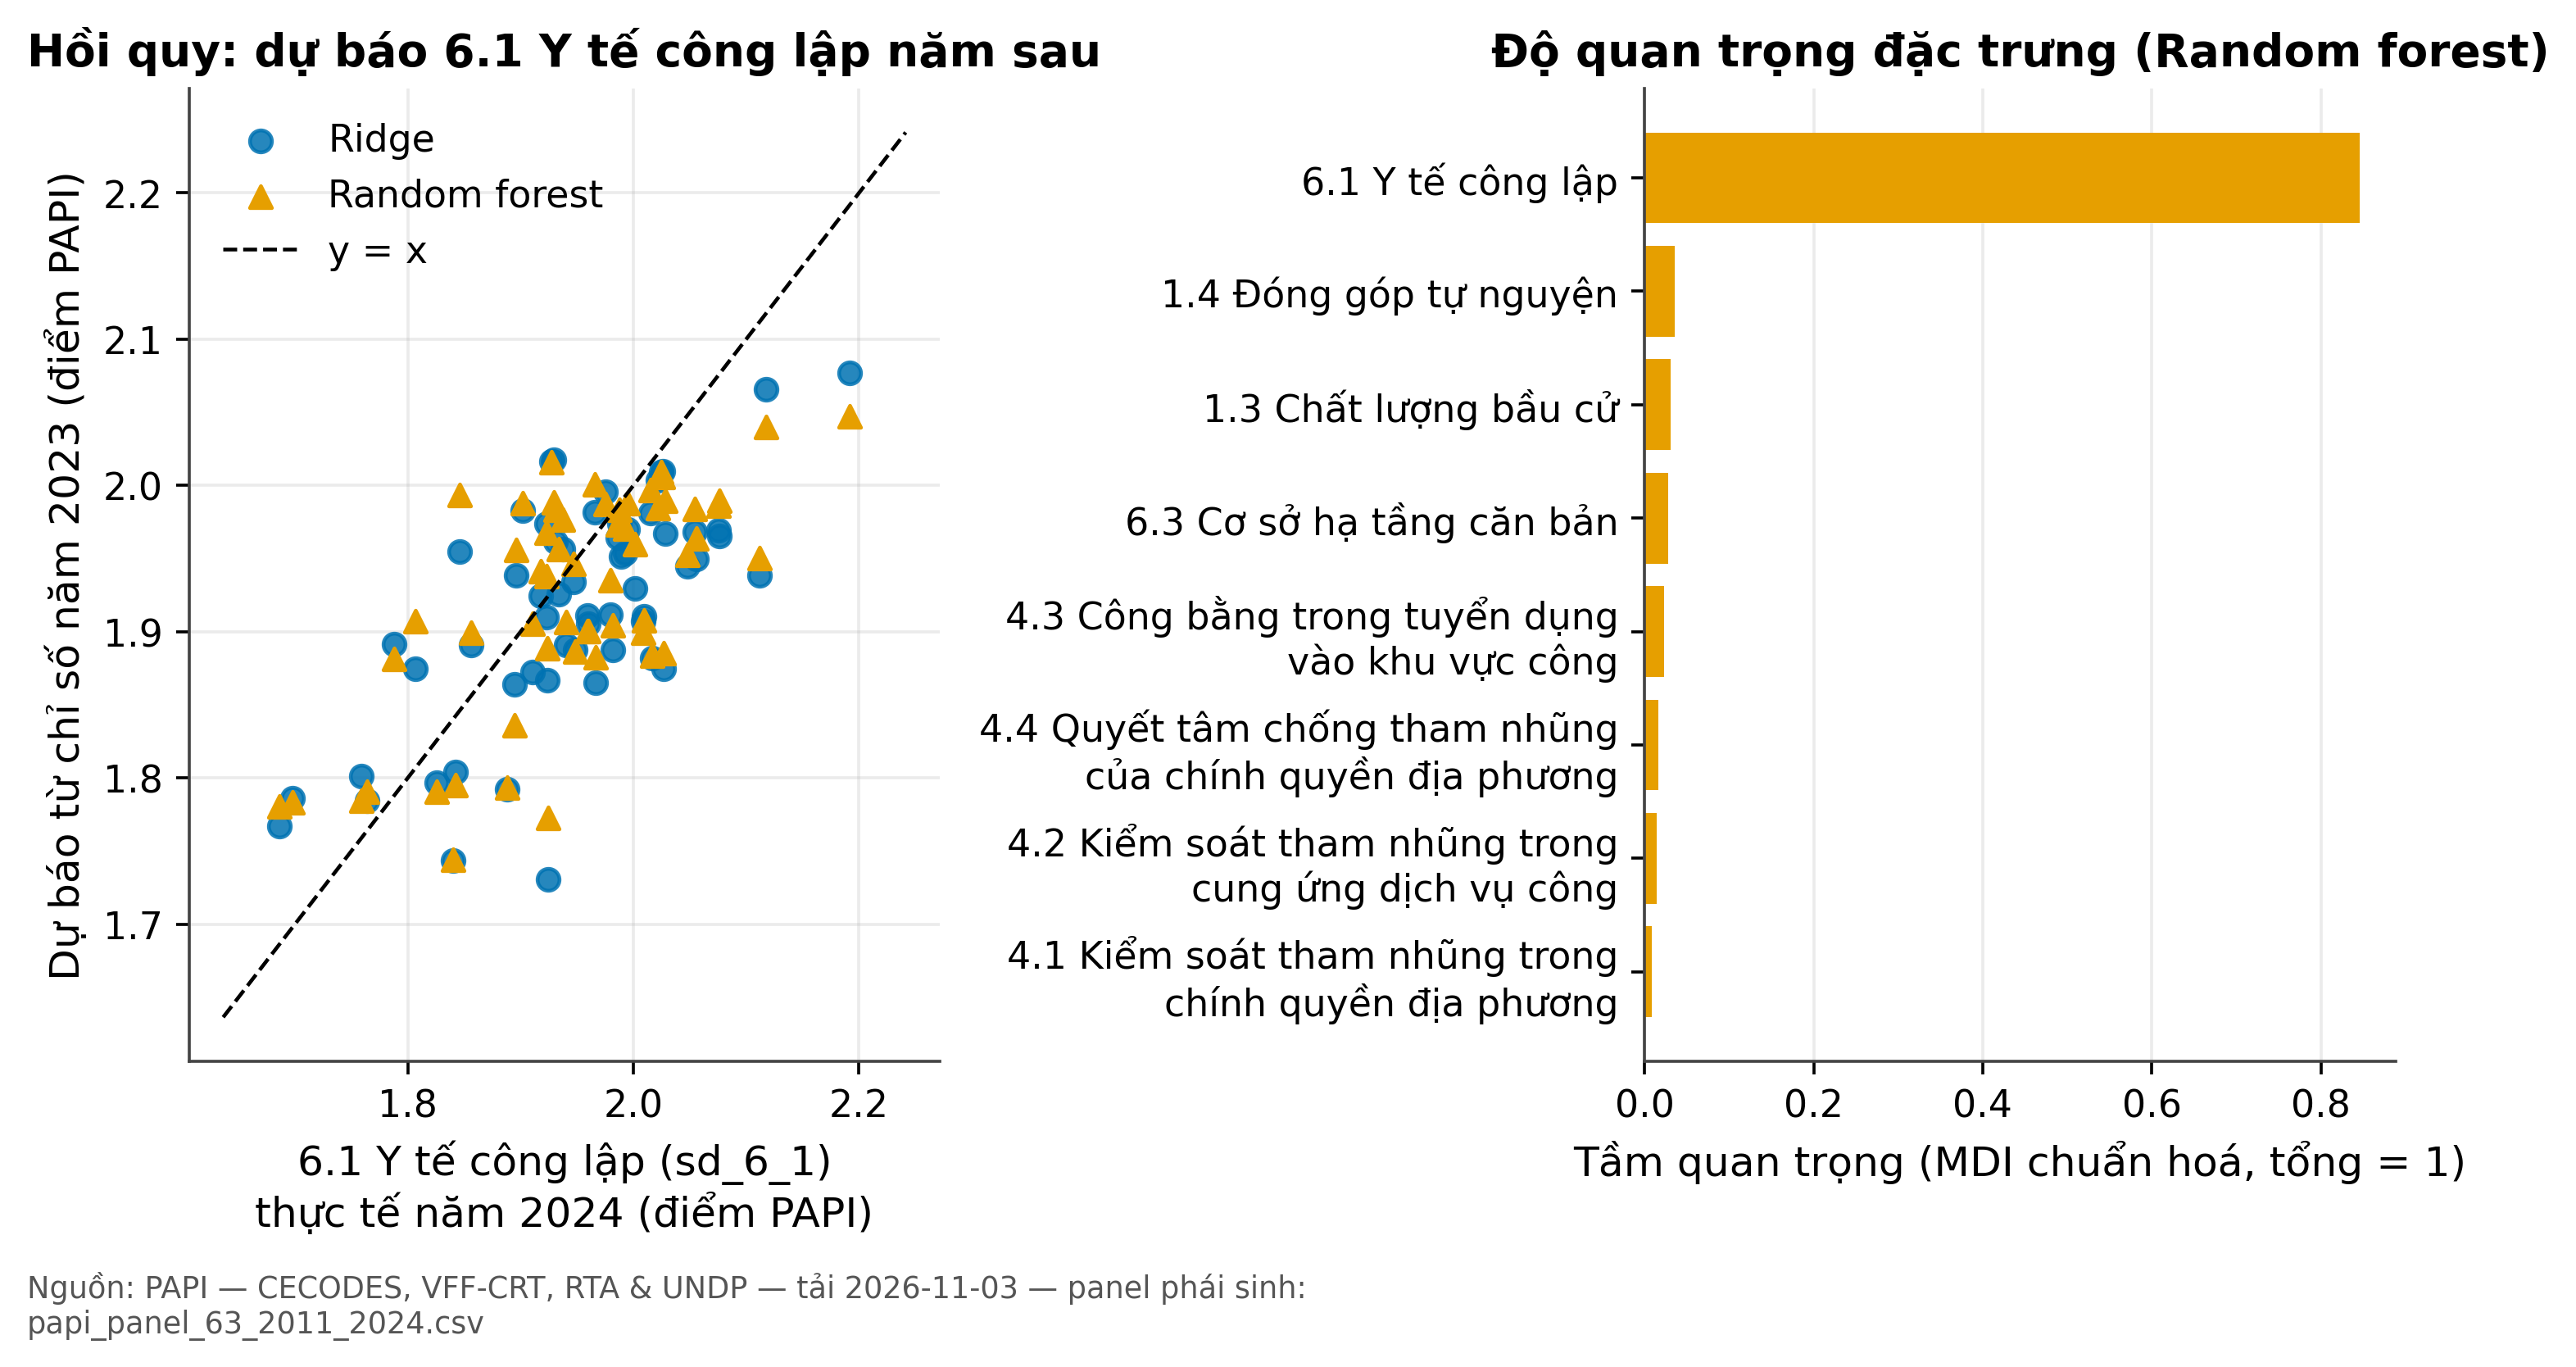

In [14]:
ridge = joblib.load(ROOT / "models" / "sup_ridge.joblib")
rf = joblib.load(ROOT / "models" / "sup_rf.joblib")

probe = np.array([[1.5, 2.6, 2.0, 2.1, 1.9, 1.7, 1.9, 1.8]])
print("8 đặc trưng đầu vào:", REGRESSION_FEATURES)
print("Vector mẫu:", probe.tolist()[0])
print(f"Dự báo 6.1 Y tế công lập năm sau — Ridge: {ridge.predict(probe)[0]:.4f} | "
      f"RF: {rf.predict(probe)[0]:.4f}")

display(Image(filename=str(ROOT / "results" / "figs" / "supervised_regression.png")))

## 6. Kết luận & hạn chế

**Kết luận:**
- STING tự viết hoạt động đúng: ARI = 0.950 trên dữ liệu tổng hợp; trên dữ liệu thật cho 1 cụm lớn
  (629) + 2 cụm li ti (16, 5) + nhiễu 19.6% — dữ liệu PAPI cấp tỉnh/năm **gần như một khối**, cấu trúc
  tách biệt chỉ ở ngoại vi.
- So sánh: ARI STING vs k-means thấp (0.07–0.17); STING đồng thuận với DBSCAN(eps=0.2) hơn (ARI ≈ 0.65)
  — cùng họ mật độ-lưới.
- Mô hình giám sát: Ridge chọn theo CV (R²=0.265), MAE holdout 2023→2024 thấp hơn carry-forward 6.3%.

**Hạn chế (trung thực):**
- Lưới song song trục; metric hình học (silhouette/DB/CH) không bản địa với lưới — chỉ so sánh thô, tách noise.
- Cấu trúc “k=3” thực chất là 1 cụm khổng lồ + 2 cụm li ti; 2 cụm li ti chỉ có điểm 2011–2018 (concept drift).
- Một holdout 2023→2024 chưa đủ để khẳng định năng lực dự báo tổng quát; lợi thế so với carry-forward chủ yếu
  là thông tin lag-1 của chính target (xem `results/supervised_summary.md`).
- 23/37 chỉ tiêu bị đánh dấu bởi kiểm tra heuristic (bước nhảy trung bình > 0.25); chưa chứng minh là
  đổi thang — giới hạn phân tích xuyên năm. Ví dụ đã đối chiếu workbook: `sd_5_4` (đổi thang 2021;
  `data/raw/papi/PROVENANCE.md`).

**Tài liệu tham khảo:** Wang, Yang & Muntz (VLDB'97); PAPI (CECODES/VFF-CRT/RTA/UNDP);
Le et al., Mendeley Data (DOI 10.17632/wbk42j9wc8.1, CC BY 4.0).